# Exploratory Data Analysis — UCI Heart Disease (Cleveland)

Goal: understand feature distributions, data quality and which features separate patients with and without heart disease, to guide feature engineering and model choice.

Input: `data/processed/heart_clean.csv` produced by `python -m src.data`. All figures are saved to `screenshots/eda/` for the report.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import (CLEAN_DATA_PATH, NUMERIC_FEATURES, BINARY_FEATURES,
                        CATEGORICAL_FEATURES, TARGET)

FIG_DIR = ROOT / 'screenshots' / 'eda'
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {0: '#4C9F70', 1: '#D1495B'}   # green = healthy, red = disease
LABELS = {0: 'No disease', 1: 'Disease'}

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

df = pd.read_csv(CLEAN_DATA_PATH)
df.shape

(303, 14)

## 1. Overview and data quality

In [2]:
df.head()

,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang,cp,restecg,slope,thal,target
0,63.0,145.0,233.0,150.0,2.3,0.0,1,1,0,1,2,3,6.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,1,0,1,4,2,2,3.0,1
2,67.0,120.0,229.0,129.0,2.6,2.0,1,0,1,4,2,2,7.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,1,0,0,3,0,3,3.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0,0,0,2,2,1,3.0,0


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0


In [4]:
missing = df.isna().sum()
missing[missing > 0].to_frame('missing_count')

,missing_count
ca,4
thal,2


Only `ca` (4 rows) and `thal` (2 rows) have missing values — under 2% of rows. They are imputed inside the training pipeline (median for numeric, most-frequent for categorical) rather than dropped.

## 2. Class balance

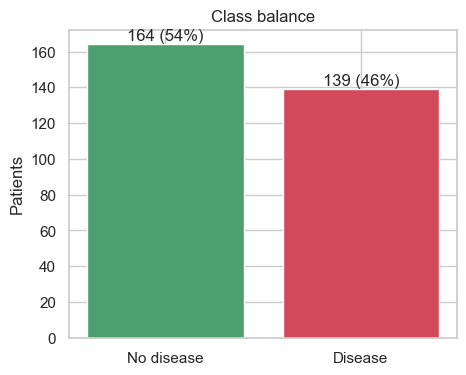

In [5]:
counts = df[TARGET].map(LABELS).value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values,
              color=[PALETTE[0] if l == 'No disease' else PALETTE[1] for l in counts.index])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f'{v} ({v / len(df):.0%})', ha='center')
ax.set_title('Class balance'); ax.set_ylabel('Patients')
save(fig, '01_class_balance'); plt.show()

The classes are roughly balanced (~54% / 46%), so accuracy is a meaningful metric and no resampling is needed. Stratified splits will still be used to keep the ratio stable.

## 3. Numeric feature distributions

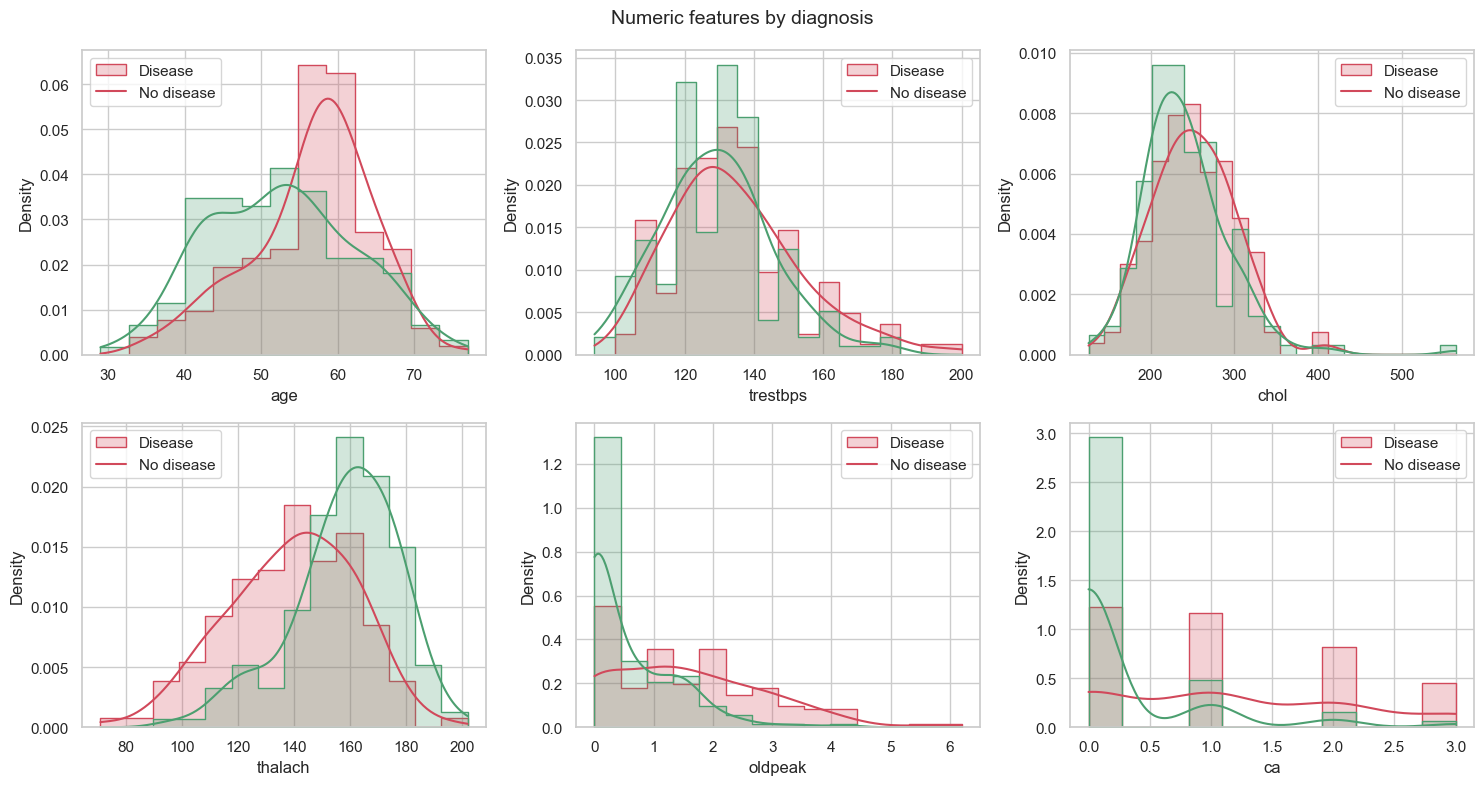

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, palette=PALETTE, kde=True,
                 element='step', stat='density', common_norm=False, ax=ax)
    ax.legend(labels=[LABELS[1], LABELS[0]], title=None)
fig.suptitle('Numeric features by diagnosis', fontsize=14)
fig.tight_layout(); save(fig, '02_numeric_histograms'); plt.show()

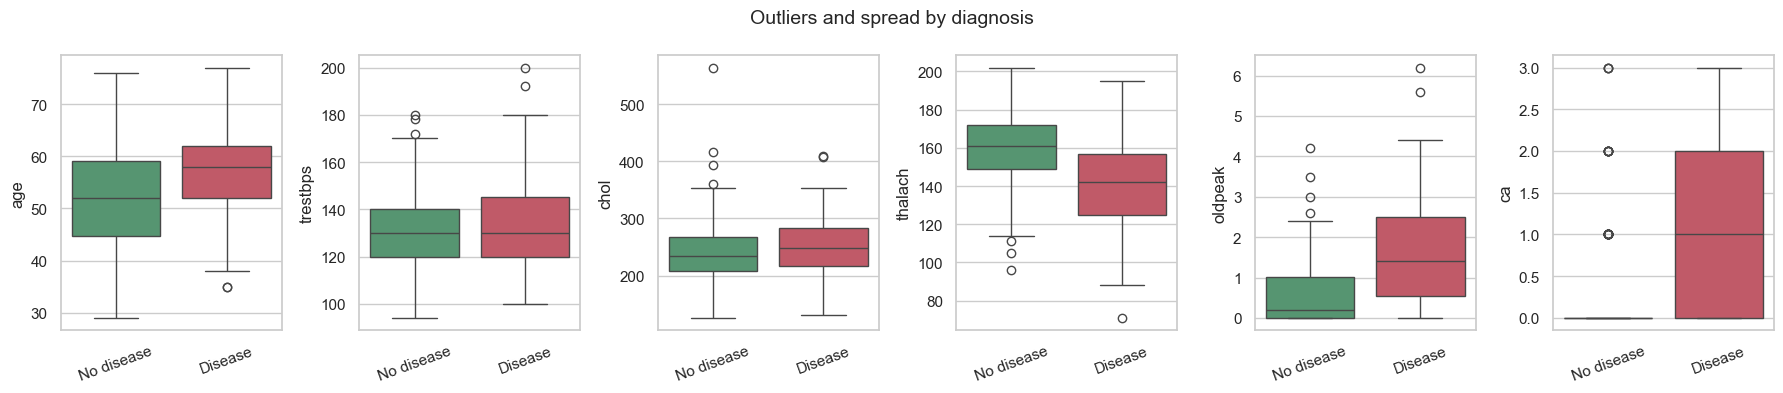

In [7]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETTE, legend=False, ax=ax)
    ax.set_xticks([0, 1], [LABELS[0], LABELS[1]], rotation=20); ax.set_xlabel('')
fig.suptitle('Outliers and spread by diagnosis', fontsize=14)
fig.tight_layout(); save(fig, '03_numeric_boxplots'); plt.show()

Observations:
- `thalach` (max heart rate) is clearly **lower** in diseased patients.
- `oldpeak` and `ca` are clearly **higher** in diseased patients.
- `chol` and `trestbps` overlap heavily — weak on their own — and contain a few high outliers (e.g. cholesterol > 500). Outliers are plausible clinical values, so they are kept; scaling handles the range differences.
- Features are on very different scales (oldpeak 0–6 vs chol 100–560) → standard scaling is needed for distance/gradient-based models like Logistic Regression.

## 4. Categorical and binary features

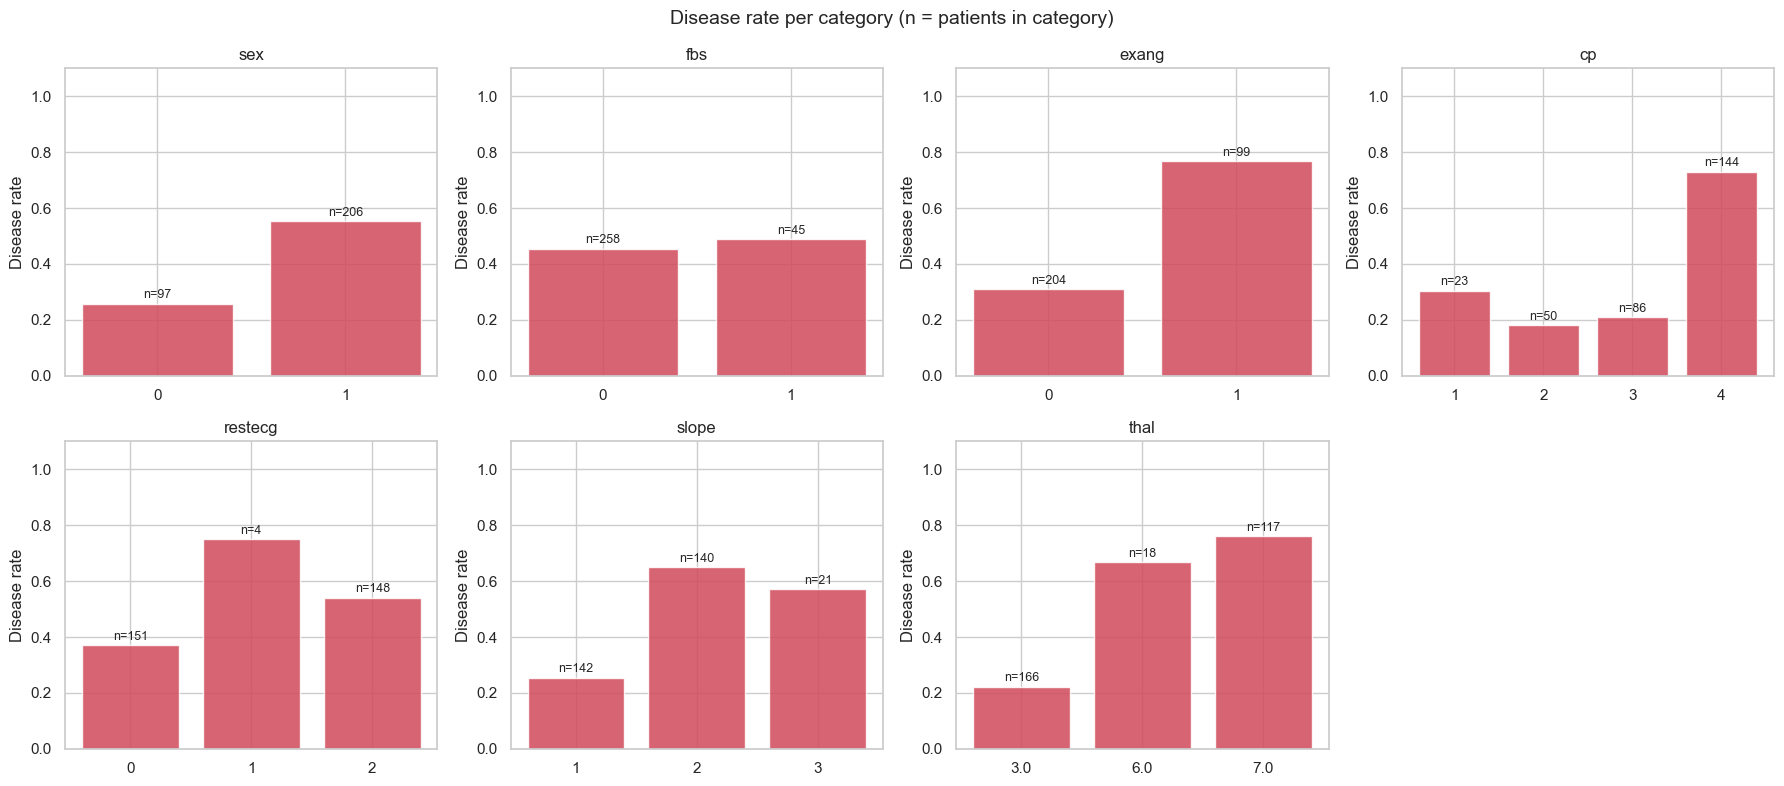

In [8]:
cat_cols = BINARY_FEATURES + CATEGORICAL_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)[TARGET].agg(['mean', 'size'])
    ax.bar(rate.index.astype(str), rate['mean'], color='#D1495B', alpha=0.85)
    for i, (m, n) in enumerate(zip(rate['mean'], rate['size'])):
        ax.text(i, m + 0.02, f'n={n}', ha='center', fontsize=9)
    ax.set_ylim(0, 1.1); ax.set_title(col); ax.set_ylabel('Disease rate')
axes.flat[-1].axis('off')
fig.suptitle('Disease rate per category (n = patients in category)', fontsize=14)
fig.tight_layout(); save(fig, '04_categorical_disease_rate'); plt.show()

Observations:
- `cp = 4` (asymptomatic chest pain) has a far higher disease rate than other types.
- `thal = 7` (reversible defect) and `exang = 1` (exercise angina) are strong risk signals.
- `fbs` shows almost no difference → likely a weak feature.
- `restecg = 1` has only 4 patients and `thal = 6` only 18 → rare categories; their disease rates are unreliable, and the encoder must tolerate unseen categories.
- `cp`, `restecg`, `slope`, `thal` are **nominal codes**, not ordered quantities, so they will be **one-hot encoded** rather than used as raw numbers.

## 5. Correlation analysis

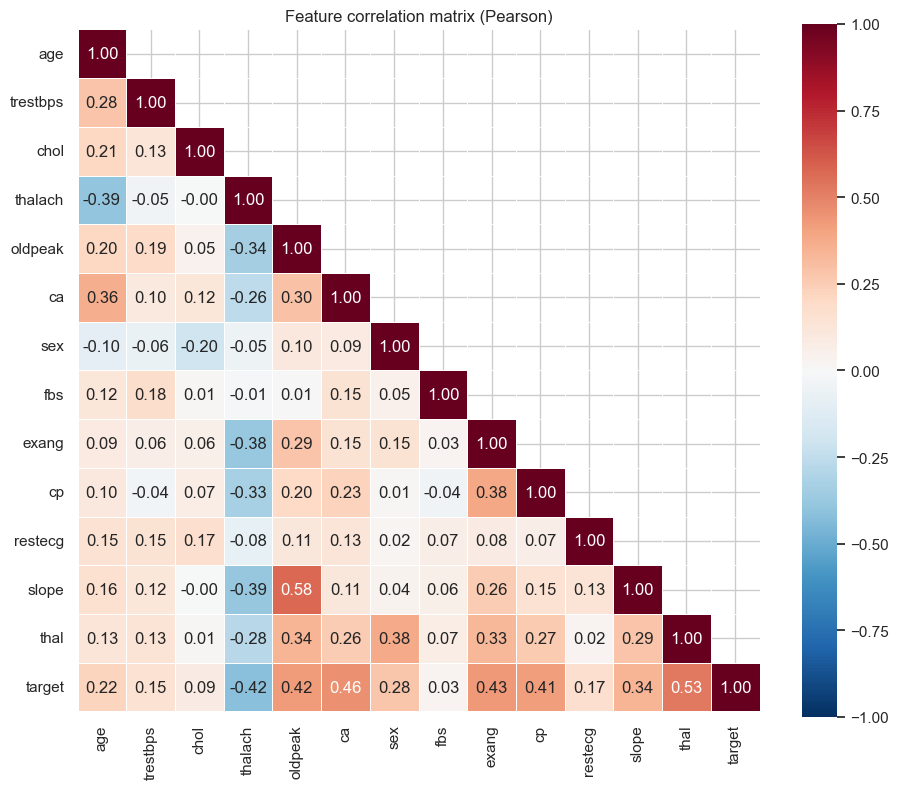

In [9]:
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Feature correlation matrix (Pearson)')
save(fig, '05_correlation_heatmap'); plt.show()

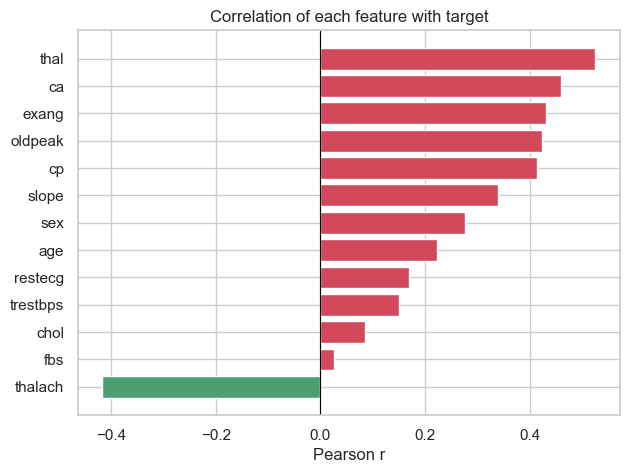

thalach    -0.417
fbs         0.025
chol        0.085
trestbps    0.151
restecg     0.169
age         0.223
sex         0.277
slope       0.339
cp          0.414
oldpeak     0.425
exang       0.432
ca          0.460
thal        0.526
Name: target, dtype: float64

In [10]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(target_corr.index, target_corr.values,
        color=['#4C9F70' if v < 0 else '#D1495B' for v in target_corr.values])
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Correlation of each feature with target'); ax.set_xlabel('Pearson r')
save(fig, '06_target_correlation'); plt.show()
target_corr.round(3)

Observations:
- Strongest relationships with the target: `thal`, `ca`, `oldpeak`, `exang`, `cp` (positive) and `thalach` (negative).
- No pair of input features is highly correlated (all |r| < 0.6), so multicollinearity is not a concern and all features are kept.
- Pearson correlation on coded categoricals is only indicative; tree models and one-hot encoding will capture non-linear effects.

## 6. Pairwise view of the strongest numeric features

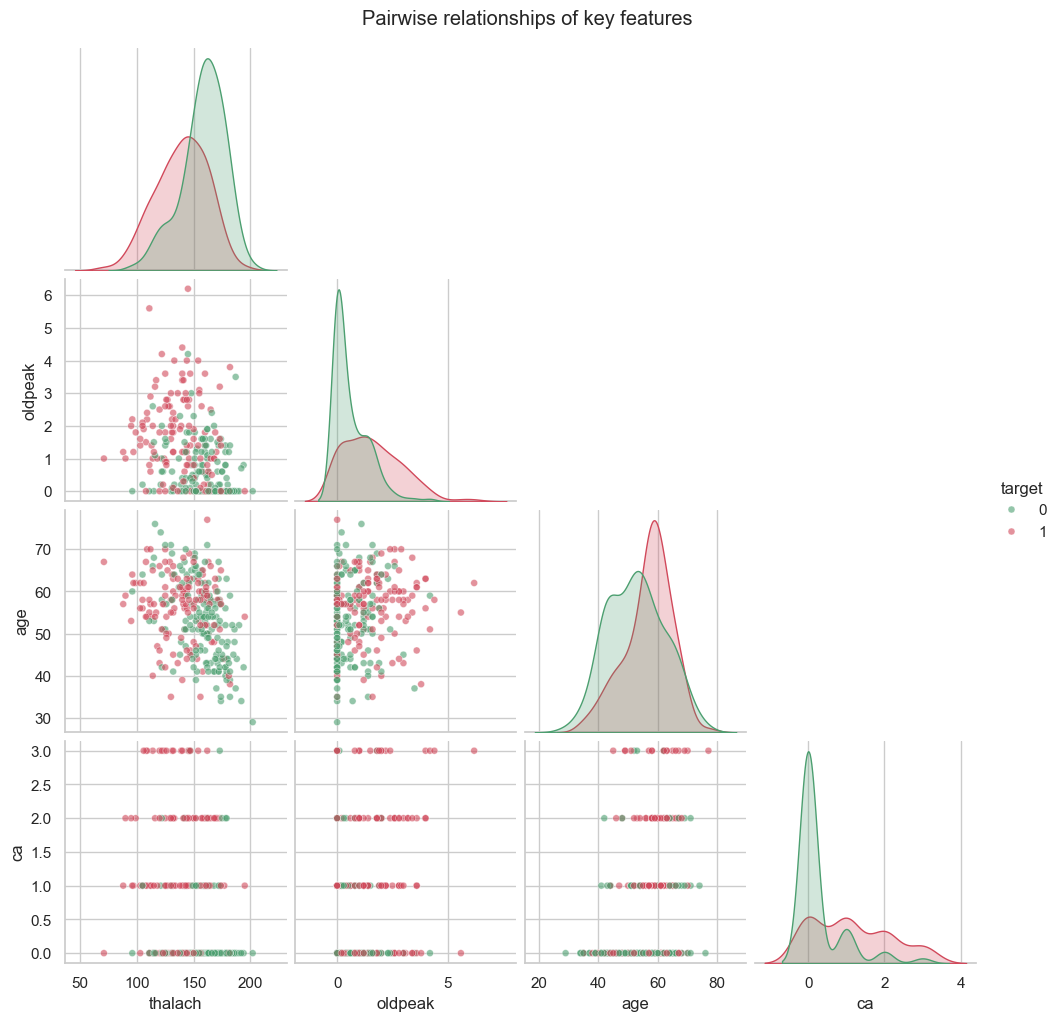

In [11]:
g = sns.pairplot(df[['thalach', 'oldpeak', 'age', 'ca', TARGET]].dropna(),
                 hue=TARGET, palette=PALETTE, corner=True, plot_kws={'alpha': 0.6, 's': 25})
g.figure.suptitle('Pairwise relationships of key features', y=1.02)
save(g.figure, '07_pairplot'); plt.show()

## 7. Summary → decisions for modelling

| Finding | Decision |
|---|---|
| <2% missing, only in `ca`, `thal` | Impute in pipeline (median / most-frequent) |
| Balanced classes (54/46) | No resampling; stratified CV; report accuracy, precision, recall, ROC-AUC |
| Numeric features on very different scales | `StandardScaler` on numeric features |
| `cp`, `restecg`, `slope`, `thal` are nominal codes | `OneHotEncoder` (handle_unknown='ignore') |
| Outliers are clinically plausible | Keep them; prefer robust models |
| Mix of linear (`thalach`) and threshold-like (`cp=4`, `thal=7`) signals | Compare a linear model (Logistic Regression) with tree ensembles (Random Forest, Gradient Boosting) |